In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('videos.csv')
df['published_at'] = pd.to_datetime(df['published_at'])

print(f"Total videos: {len(df)}")
print(f"Average views: {int(df['views'].mean()):,}")
print(f"Median views: {int(df['views'].median()):,}")
df[['views', 'likes', 'comments', 'duration_min']].describe().round(0)

Total videos: 232
Average views: 436,542
Median views: 293,535


,views,likes,comments,duration_min
count,232.0,232.0,232.0,232.0
mean,436543.0,11634.0,1141.0,78.0
std,569861.0,13514.0,1025.0,23.0
min,14622.0,385.0,12.0,1.0
25%,169156.0,5299.0,509.0,74.0
50%,293536.0,8324.0,914.0,82.0
75%,513141.0,14269.0,1466.0,90.0
max,6661923.0,167506.0,10699.0,121.0


In [5]:
print("Top 10 by views:")
top_views = df.nlargest(10, 'views')[['title', 'views', 'likes', 'duration_min', 'published_at']]
display(top_views)

print("\nTop 10 by like-ratio:")
top_ratio = df.nlargest(10, 'like_ratio')[['title', 'views', 'like_ratio', 'duration_min']]
display(top_ratio)

Top 10 by views:


,title,views,likes,duration_min,published_at
229,"ФИЗИК Семихатов: Квантовые парадоксы, Мультивс...",6661923,167506,82.28,2022-08-12 14:00:32+00:00
136,"АСТРОФИЗИК Асташёнок: МАШИНА ВРЕМЕНИ, КВАНТОВА...",2544433,38202,85.40,2024-02-25 14:56:20+00:00
152,БОЛЬШОГО ВЗРЫВА НЕ БЫЛО?,2482235,39761,79.53,2023-10-29 13:34:50+00:00
165,СЕМИХАТОВ: Загадка времени и Микромира,2098350,46509,83.50,2023-07-30 11:54:03+00:00
125,АСТРОФИЗИК Штерн: ПУТЕШЕСТВИЕ в ДАЛЬНИЙ КОСМОС...,1905468,34774,47.53,2024-05-19 13:50:07+00:00
224,"АСТРОФИЗИК Сергей Попов: Черные дыры, Вселенна...",1866466,37336,91.92,2022-09-16 17:08:13+00:00
115,СЕМИХАТОВ: УСТРОЙСТВО МУЛЬТИВСЕЛЕННОЙ,1543936,27571,109.10,2024-07-28 11:46:14+00:00
184,БИОЛОГ Никитин: ЖИЗНЬ ДО ЖИЗНИ,1428808,34791,94.22,2023-03-18 15:15:38+00:00
87,АЛЕКСЕЙ ВОДОВОЗОВ: ГЛАВНЫЕ МИФЫ О ВРЕДНЫХ ПРИВ...,1378701,33248,72.48,2025-02-09 14:48:55+00:00
166,ВЯЛОВ: АЛКОГОЛЬ - ЧТО МЫ ПЬЁМ?,1365913,41355,56.80,2023-07-23 17:32:40+00:00



Top 10 by like-ratio:


,title,views,like_ratio,duration_min
122,"ТАЙНЫ Японии: РЕЛИГИЯ, ИЕРОГЛИФЫ, ЧЕБУРАШКА, Е...",226365,0.052698,88.37
214,НАСИЛИЕ в ВИДЕО ИГРАХ и GTA 6,88135,0.051841,91.45
231,"КИНОКРИТИК Коршунов: НАСИЛИЕ и МАТ в кино, ПОС...",122304,0.051789,71.72
133,"Афонина: ЯЗЫК 1000 ЛЕТ НАЗАД, МАТ и ПУШКИН",288414,0.051308,81.73
215,ПОЛИГЛОТ Дмитрий Петров: Как языки влияют на нас?,742835,0.050883,65.02
185,"СКУРАТОВСКАЯ: МУЖЧИНЫ В ЮБКАХ, ТОПЛЕС БУДУЩЕЕ",78815,0.050333,68.22
172,ЧТО МЫ ЕДИМ?,417176,0.048802,94.00
135,"ВОСКОБОЙНИКОВ: МИФЫ О РУСИ, МАТ на БЕРЕСТЯНЫХ ...",199501,0.048712,64.60
213,"ЖЕНЯ ТИМОНОВА: Эволюция, Конформизм, Оргазм (В...",344030,0.047179,70.88
132,"ПСИХОТЕРАПЕВТ: ВСЕ ОТ РОДИТЕЛЕЙ? ГАЗЛАЙТИНГ, В...",189798,0.046808,79.65


,video_count,avg_views,avg_like_ratio
duration_group,,,
Long (>60 min),211,454191.815,0.030
Medium (5-60 min),6,714864.833,0.027
Shorts (<5 min),15,76948.400,0.031


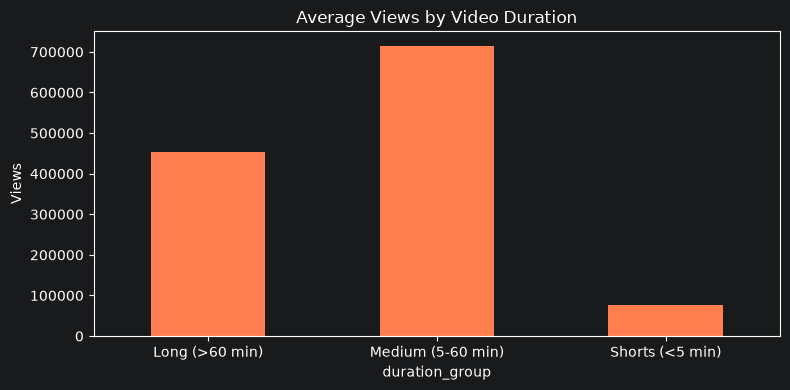

In [12]:
def duration_group(m):
    if m < 5: return "Shorts (<5 min)"
    elif m < 60: return "Medium (5-60 min)"
    else: return "Long (>60 min)"

df['duration_group'] = df['duration_min'].apply(duration_group)

dur_stats = df.groupby('duration_group').agg(
    video_count=('video_id', 'count'),
    avg_views=('views', 'mean'),
    avg_like_ratio=('like_ratio', 'mean')
).round(3)

display(dur_stats)

fig, ax = plt.subplots(figsize=(8, 4))
dur_stats['avg_views'].plot(kind='bar', ax=ax, color='coral')
ax.set_title("Average Views by Video Duration")
ax.set_ylabel("Views")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

df['year_month'] = df['published_at'].dt.tz_localize(None).dt.to_period('M')

monthly_stats = df.groupby('year_month').agg(
    video_count=('video_id', 'count'),
    avg_views=('views', 'mean'),
    avg_like_ratio=('like_ratio', 'mean')
).reset_index()

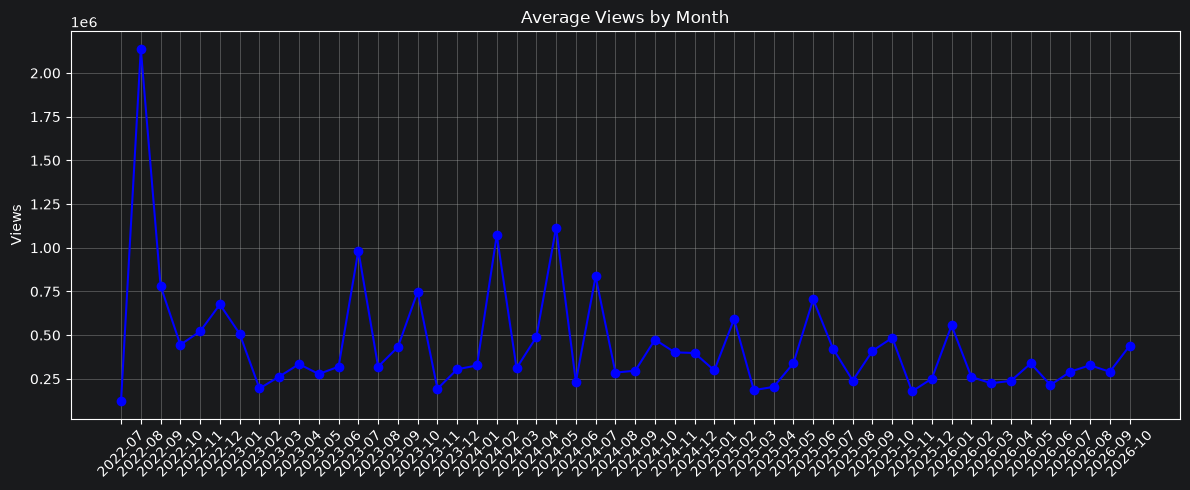

Correlation with all data: 0.152


In [8]:
monthly_stats['year_month'] = monthly_stats['year_month'].astype(str)

# Plot
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_stats['year_month'], monthly_stats['avg_views'], marker='o', color='b')
ax.set_title("Average Views by Month")
ax.set_ylabel("Views")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


corr_all = df['duration_min'].corr(df['views'])
print(f"Correlation with all data: {corr_all:.3f}")

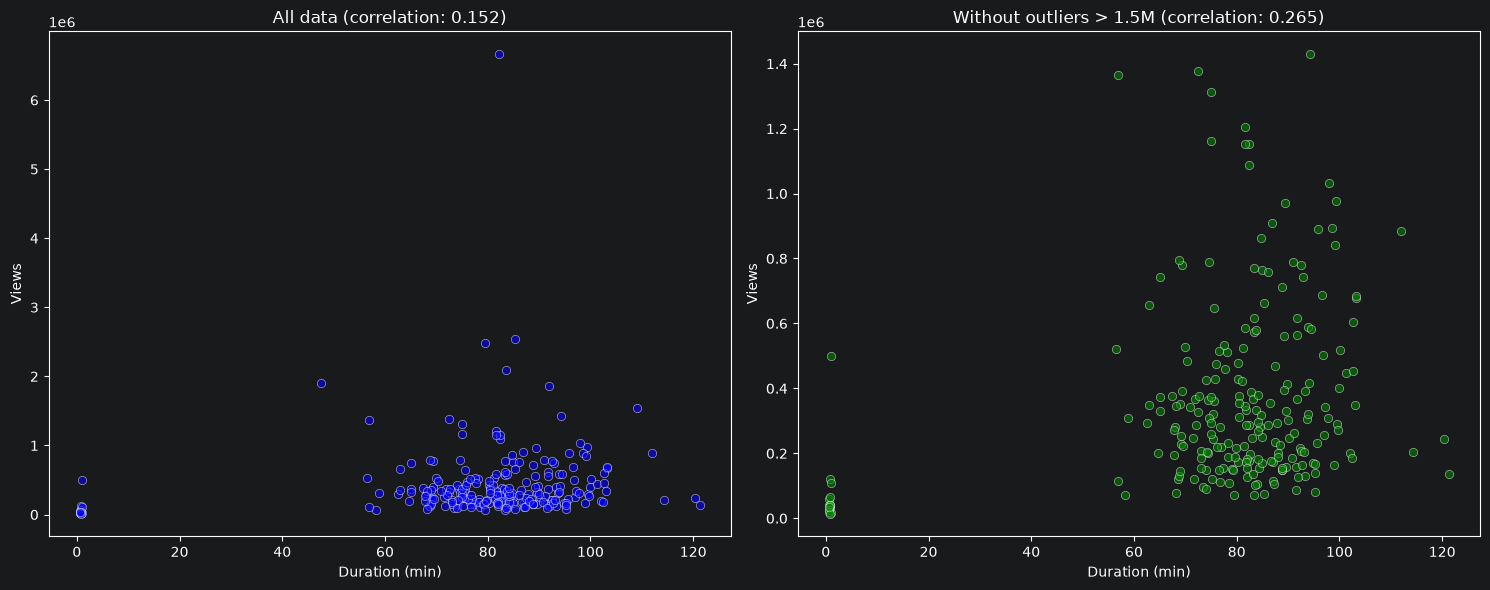

In [10]:
# videos with less than 1.5 million views
df_clean = df[df['views'] < 1500000]
corr_clean = df_clean['duration_min'].corr(df_clean['views'])

# Plot 1
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(data=df, x='duration_min', y='views', alpha=0.6, ax=axes[0], color='blue')
axes[0].set_title(f"All data (correlation: {corr_all:.3f})")
axes[0].set_xlabel("Duration (min)")
axes[0].set_ylabel("Views")

# Plot 2
sns.scatterplot(data=df_clean, x='duration_min', y='views', alpha=0.6, ax=axes[1], color='green')
axes[1].set_title(f"Without outliers > 1.5M (correlation: {corr_clean:.3f})")
axes[1].set_xlabel("Duration (min)")
axes[1].set_ylabel("Views")

plt.tight_layout()
plt.show()